In [1]:

import pandas as pd

print("Pandas version:", pd.__version__)


Pandas version: 2.2.3


In [4]:

from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())



Saving blinkit_customer_feedback.csv to blinkit_customer_feedback.csv
Saving blinkit_customers.csv to blinkit_customers.csv
Saving blinkit_delivery_performance.csv to blinkit_delivery_performance.csv
Saving blinkit_inventory.csv to blinkit_inventory.csv
Saving blinkit_inventoryNew.csv to blinkit_inventoryNew.csv
Saving blinkit_marketing_performance.csv to blinkit_marketing_performance.csv
Saving blinkit_order_items.csv to blinkit_order_items.csv
Saving blinkit_orders.csv to blinkit_orders.csv
Saving blinkit_products.csv to blinkit_products.csv
Saving Category_Icons.xlsx to Category_Icons.xlsx
Saving Rating_Icon.xlsx to Rating_Icon.xlsx
Dataset shape: (5000, 8)


,feedback_id,order_id,customer_id,rating,feedback_text,feedback_category,sentiment,feedback_date
0,2234710,1961864118,30065862,4,"It was okay, nothing special.",Delivery,Neutral,2024-07-17
1,5450964,1549769649,9573071,3,The order was incorrect.,App Experience,Negative,2024-05-28
2,482108,9185164487,45477575,3,"It was okay, nothing special.",App Experience,Neutral,2024-09-23
3,4823104,9644738826,88067569,4,The product met my expectations.,App Experience,Neutral,2023-11-24
4,3537464,5427684290,83298567,3,Product was damaged during delivery.,Delivery,Negative,2023-11-20


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:

feedback = pd.read_csv("blinkit_customer_feedback.csv")
customers = pd.read_csv("blinkit_customers.csv")
delivery = pd.read_csv("blinkit_delivery_performance.csv")
inventory = pd.read_csv("blinkit_inventory.csv")
inventory_new = pd.read_csv("blinkit_inventoryNew.csv")
marketing = pd.read_csv("blinkit_marketing_performance.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [6]:

datasets = {
    "Feedback": feedback,
    "Customers": customers,
    "Delivery": delivery,
    "Inventory": inventory,
    "Inventory New": inventory_new,
    "Marketing": marketing
}

for name, data in datasets.items():
    print("\nDataset:", name)
    print("Rows and columns:", data.shape)
    print("Columns:", list(data.columns))



Dataset: Feedback
Rows and columns: (5000, 8)
Columns: ['feedback_id', 'order_id', 'customer_id', 'rating', 'feedback_text', 'feedback_category', 'sentiment', 'feedback_date']

Dataset: Customers
Rows and columns: (2500, 11)
Columns: ['customer_id', 'customer_name', 'email', 'phone', 'address', 'area', 'pincode', 'registration_date', 'customer_segment', 'total_orders', 'avg_order_value']

Dataset: Delivery
Rows and columns: (5000, 8)
Columns: ['order_id', 'delivery_partner_id', 'promised_time', 'actual_time', 'delivery_time_minutes', 'distance_km', 'delivery_status', 'reasons_if_delayed']

Dataset: Inventory
Rows and columns: (75172, 4)
Columns: ['product_id', 'date', 'stock_received', 'damaged_stock']

Dataset: Inventory New
Rows and columns: (18105, 4)
Columns: ['product_id', 'date', 'stock_received', 'damaged_stock']

Dataset: Marketing
Rows and columns: (5400, 11)
Columns: ['campaign_id', 'campaign_name', 'date', 'target_audience', 'channel', 'impressions', 'clicks', 'conversions'

In [7]:

datasets = {
    "Feedback": feedback,
    "Customers": customers,
    "Delivery": delivery,
    "Inventory": inventory,
    "Inventory New": inventory_new,
    "Marketing": marketing
}

quality_report = []

for name, data in datasets.items():

    quality_report.append({
        "Dataset": name,
        "Total Rows": len(data),
        "Total Columns": len(data.columns),
        "Missing Values": data.isnull().sum().sum(),
        "Duplicate Rows": data.duplicated().sum()
    })

quality_df = pd.DataFrame(quality_report)

display(quality_df)


,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Rows
0,Feedback,5000,8,0,0
1,Customers,2500,11,0,0
2,Delivery,5000,8,1902,0
3,Inventory,75172,4,0,0
4,Inventory New,18105,4,0,7359
5,Marketing,5400,11,0,0


In [8]:

delivery.isnull().sum()


,0
order_id,0
delivery_partner_id,0
promised_time,0
actual_time,0
delivery_time_minutes,0
distance_km,0
delivery_status,0
reasons_if_delayed,1902


In [9]:

delivery.groupby(
    "delivery_status"
)["reasons_if_delayed"].apply(
    lambda x: x.isnull().sum()
)


,reasons_if_delayed
delivery_status,
On Time,1902
Significantly Delayed,0
Slightly Delayed,0


In [10]:

print(delivery["delivery_status"].value_counts())


delivery_status
On Time                  3470
Slightly Delayed         1037
Significantly Delayed     493
Name: count, dtype: int64


In [11]:

print("Total records:", len(inventory_new))
print("Duplicate records:", inventory_new.duplicated().sum())

display(
    inventory_new[
        inventory_new.duplicated(keep=False)
    ].head(10)
)


Total records: 18105
Duplicate records: 7359


,product_id,date,stock_received,damaged_stock
11,888807,Mar-23,1,0
16,324809,Mar-23,1,0
21,990993,Mar-23,1,0
40,287070,Mar-23,1,0
46,677542,Mar-23,1,0
47,604184,Mar-23,1,0
59,661577,Mar-23,3,0
66,425341,Mar-23,1,0
72,818990,Mar-23,1,0
77,329351,Mar-23,3,0


In [12]:

inventory_new_clean = inventory_new.drop_duplicates().copy()

print("Original rows:", len(inventory_new))
print("Cleaned rows:", len(inventory_new_clean))
print("Remaining duplicates:",
      inventory_new_clean.duplicated().sum())


Original rows: 18105
Cleaned rows: 10746
Remaining duplicates: 0


In [13]:

inventory_clean = inventory.copy()
inventory_new_clean = inventory_new_clean.copy()

inventory_clean["date"] = pd.to_datetime(
    inventory_clean["date"],
    format="%d-%m-%Y",
    errors="coerce"
)

inventory_new_clean["date"] = pd.to_datetime(
    inventory_new_clean["date"],
    format="%b-%y",
    errors="coerce"
)

print(inventory_clean["date"].dtype)
print(inventory_new_clean["date"].dtype)


datetime64[ns]
datetime64[ns]


In [14]:

delivery_check = delivery.copy()

delivery_check["promised_time"] = pd.to_datetime(
    delivery_check["promised_time"],
    errors="coerce"
)

delivery_check["actual_time"] = pd.to_datetime(
    delivery_check["actual_time"],
    errors="coerce"
)

delivery_check["calculated_delay"] = (
    delivery_check["actual_time"] -
    delivery_check["promised_time"]
).dt.total_seconds() / 60

display(
    delivery_check[
        ["promised_time",
         "actual_time",
         "delivery_time_minutes",
         "calculated_delay"]
    ].head(10)
)


,promised_time,actual_time,delivery_time_minutes,calculated_delay
0,2024-07-17 08:52:01,2024-07-17 08:47:01,-5.0,-5.0
1,2024-05-28 13:25:29,2024-05-28 13:27:29,2.0,2.0
2,2024-09-23 13:25:12,2024-09-23 13:29:12,4.0,4.0
3,2023-11-24 16:34:56,2023-11-24 16:33:56,-1.0,-1.0
4,2023-11-20 05:17:39,2023-11-20 05:18:39,1.0,1.0
5,2023-03-18 16:49:51,2023-03-18 16:48:51,-1.0,-1.0
6,2023-04-16 19:01:37,2023-04-16 19:02:37,1.0,1.0
7,2024-03-31 06:37:48,2024-03-31 06:39:48,2.0,2.0
8,2023-07-14 00:02:36,2023-07-14 00:05:36,3.0,3.0
9,2023-08-09 01:37:30,2023-08-09 01:44:30,7.0,7.0


In [15]:

feedback_clean = feedback.copy()
customers_clean = customers.copy()
delivery_clean = delivery.copy()
marketing_clean = marketing.copy()

# Mark missing delay reasons for investigation
delivery_clean["reasons_if_delayed"] = (
    delivery_clean["reasons_if_delayed"]
    .fillna("Not Provided / Not Applicable")
)

print("Analysis copies created successfully!")


Analysis copies created successfully!


In [16]:

display(customers_clean.head())

print("Total customers:", len(customers_clean))

print("\nCustomer segments:")
print(customers_clean["customer_segment"].value_counts())


,customer_id,customer_name,email,phone,address,area,pincode,registration_date,customer_segment,total_orders,avg_order_value
0,97475543,Niharika Nagi,ektataneja@example.org,912987579691,"23, Nayar Path, Bihar Sharif-154625",Udupi,321865,2023-05-13,Premium,13,451.92
1,22077605,Megha Sachar,vedant45@example.com,915123179717,"51/302, Buch Chowk\nSrinagar-570271",Aligarh,149394,2024-06-18,Inactive,4,825.48
2,47822591,Hema Bahri,samiazaan@example.com,910034076149,"941\nAnne Street, Darbhanga 186125",Begusarai,621411,2024-09-25,Regular,17,1969.81
3,79726146,Zaitra Vig,ishanvi87@example.org,916264232390,"43/94, Ghosh, Alappuzha 635655",Kozhikode,826054,2023-10-04,New,4,220.09
4,57102800,Januja Verma,atideshpande@example.org,917293526596,"06\nOm, Ambarnath 477463",Ichalkaranji,730539,2024-03-22,Inactive,14,578.14


Total customers: 2500

Customer segments:
customer_segment
Regular     639
Premium     633
New         628
Inactive    600
Name: count, dtype: int64


In [17]:

total_customers = customers_clean["customer_id"].nunique()

total_orders = customers_clean["total_orders"].sum()

average_order_value = customers_clean["avg_order_value"].mean()

estimated_customer_value = (
    customers_clean["total_orders"] *
    customers_clean["avg_order_value"]
)

total_estimated_value = estimated_customer_value.sum()

print("Total Customers:", total_customers)
print("Total Orders:", total_orders)
print("Average Order Value:", round(average_order_value, 2))
print("Estimated Customer Value:", round(total_estimated_value, 2))


Total Customers: 2500
Total Orders: 26229
Average Order Value: 1102.38
Estimated Customer Value: 29027094.21


In [18]:

customers_clean["estimated_spend"] = (
    customers_clean["total_orders"] *
    customers_clean["avg_order_value"]
)

segment_analysis = (
    customers_clean.groupby("customer_segment")
    .agg(
        total_customers=("customer_id", "nunique"),
        total_orders=("total_orders", "sum"),
        avg_order_value=("avg_order_value", "mean"),
        estimated_revenue=("estimated_spend", "sum")
    )
    .reset_index()
)

segment_analysis = segment_analysis.sort_values(
    by="estimated_revenue",
    ascending=False
)

display(segment_analysis.round(2))


,customer_segment,total_customers,total_orders,avg_order_value,estimated_revenue
1,New,628,6829,1116.64,7679432.62
3,Regular,639,6598,1089.47,7158658.67
0,Inactive,600,6350,1102.15,7107041.74
2,Premium,633,6452,1101.47,7081961.18


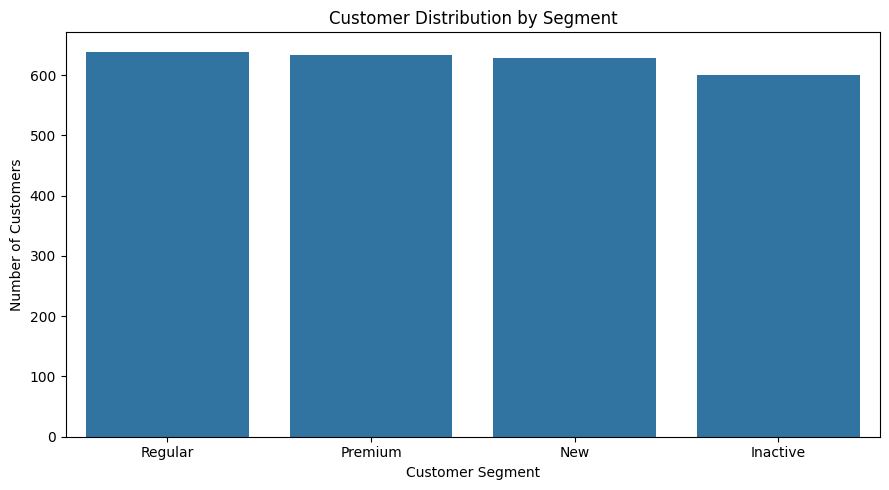

In [19]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=customers_clean,
    x="customer_segment",
    order=customers_clean["customer_segment"].value_counts().index
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


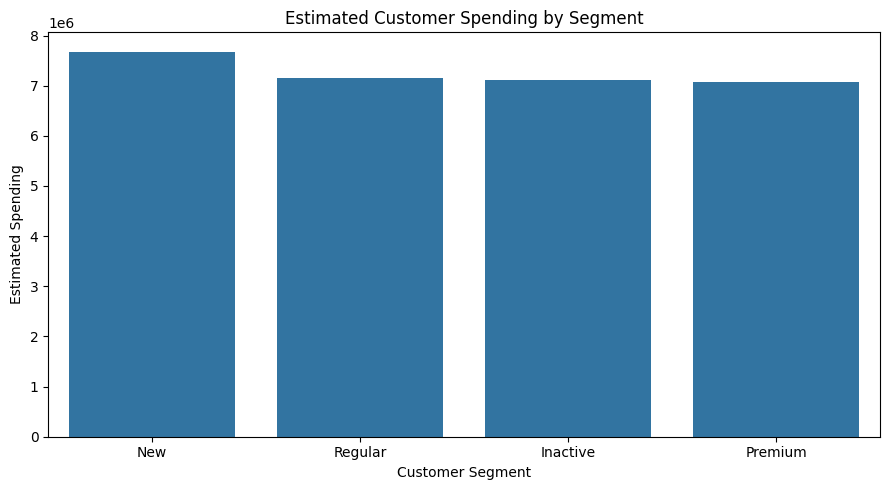

In [22]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_analysis,
    x="customer_segment",
    y="estimated_revenue"
)

plt.title("Estimated Customer Spending by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Estimated Spending")
plt.tight_layout()
plt.show()


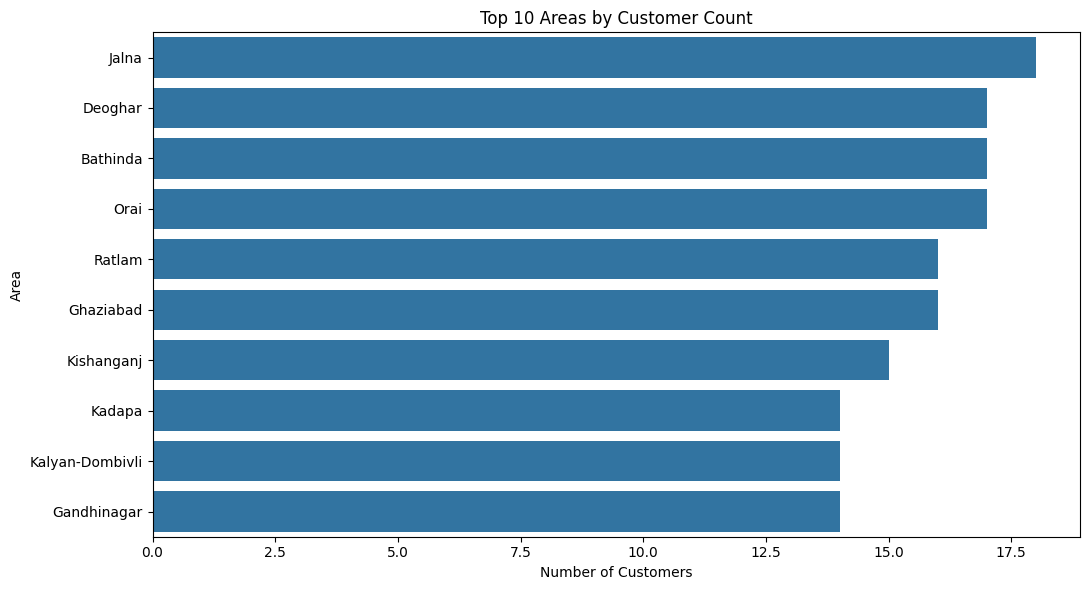

In [23]:

area_analysis = (
    customers_clean.groupby("area")
    .agg(
        total_customers=("customer_id", "nunique"),
        estimated_spending=("estimated_spend", "sum")
    )
    .reset_index()
    .sort_values(
        by="total_customers",
        ascending=False
    )
)

top_10_areas = area_analysis.head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_areas,
    x="total_customers",
    y="area"
)

plt.title("Top 10 Areas by Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("Area")
plt.tight_layout()
plt.show()


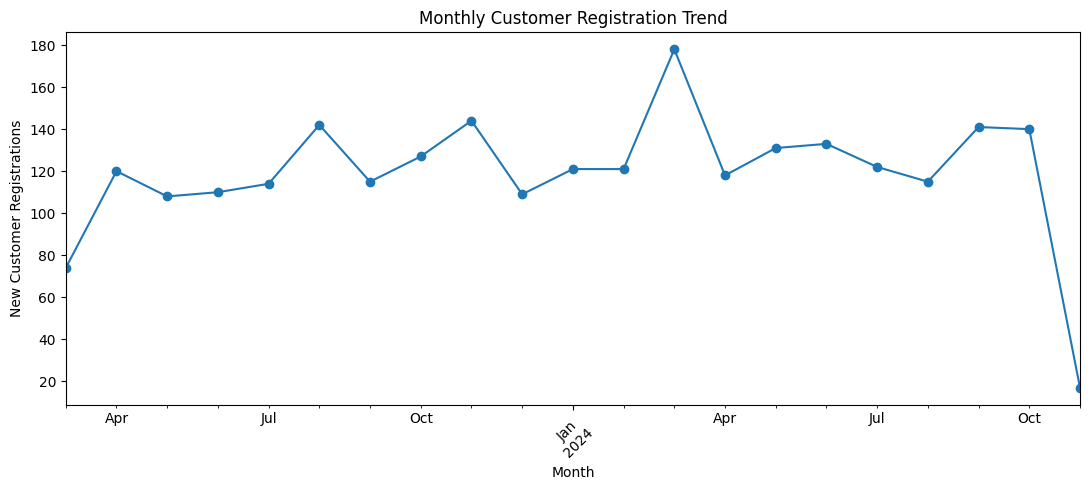

In [24]:

customers_clean["registration_date"] = pd.to_datetime(
    customers_clean["registration_date"],
    errors="coerce"
)

customers_clean["registration_month"] = (
    customers_clean["registration_date"]
    .dt.to_period("M")
)

registration_trend = (
    customers_clean.groupby("registration_month")
    ["customer_id"].nunique()
)

registration_trend.plot(
    kind="line",
    figsize=(11, 5),
    marker="o"
)

plt.title("Monthly Customer Registration Trend")
plt.xlabel("Month")
plt.ylabel("New Customer Registrations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [8]:
import pandas as pd

# Load the feedback dataset directly from file to ensure it's defined
feedback = pd.read_csv("blinkit_customer_feedback.csv")

# Create the cleaned working copy
feedback_clean = feedback.copy()
feedback_clean = feedback_clean.drop_duplicates()

# Ensure ratings are numeric
feedback_clean["rating"] = pd.to_numeric(
    feedback_clean["rating"],
    errors="coerce"
)

print("Dataset prepared successfully.")
print("Rows:", len(feedback_clean))
print("Columns:", feedback_clean.columns.tolist())

Dataset prepared successfully.
Rows: 5000
Columns: ['feedback_id', 'order_id', 'customer_id', 'rating', 'feedback_text', 'feedback_category', 'sentiment', 'feedback_date']


In [9]:
feedback_clean.head()

feedback_clean[["rating", "sentiment", "feedback_category"]].describe(include="all")


,rating,sentiment,feedback_category
count,5000.00000,5000,5000
unique,NaN,3,4
top,NaN,Neutral,Delivery
freq,NaN,1738,1271
mean,3.34440,NaN,NaN
std,1.18982,NaN,NaN
min,1.00000,NaN,NaN
25%,3.00000,NaN,NaN
50%,4.00000,NaN,NaN
75%,4.00000,NaN,NaN


In [10]:
print("Rating values:", sorted(feedback_clean["rating"].dropna().unique()))

print("\nSentiment counts:")
print(feedback_clean["sentiment"].value_counts(dropna=False))

print("\nFeedback categories:")
print(feedback_clean["feedback_category"].value_counts(dropna=False))


Rating values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Sentiment counts:
sentiment
Neutral     1738
Negative    1642
Positive    1620
Name: count, dtype: int64

Feedback categories:
feedback_category
Delivery            1271
Customer Service    1266
Product Quality     1250
App Experience      1213
Name: count, dtype: int64


In [11]:
sentiment_summary = (
    feedback_clean
    .groupby("sentiment")
    .agg(
        feedback_count=("feedback_id", "count"),
        average_rating=("rating", "mean")
    )
    .sort_values("feedback_count", ascending=False)
)

sentiment_summary

,feedback_count,average_rating
sentiment,,
Neutral,1738,3.520138
Negative,1642,2.014616
Positive,1620,4.503704


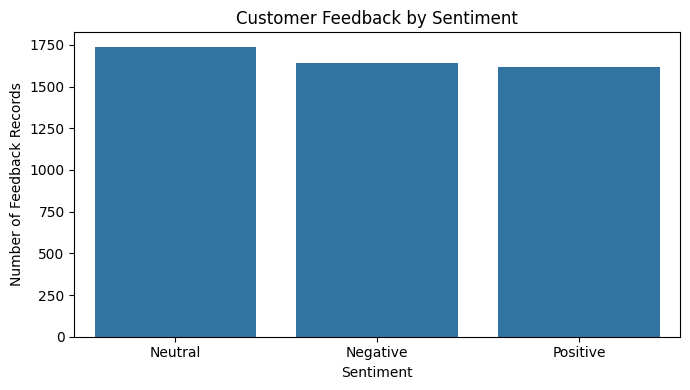

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.countplot(data=feedback_clean, x="sentiment")
plt.title("Customer Feedback by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Feedback Records")
plt.tight_layout()
plt.show()

In [13]:
category_sentiment = pd.crosstab(
    feedback_clean["feedback_category"],
    feedback_clean["sentiment"],
    normalize="index"
) * 100

category_sentiment

sentiment,Negative,Neutral,Positive
feedback_category,,,
App Experience,31.986810,34.707337,33.305853
Customer Service,32.938389,34.044234,33.017378
Delivery,31.864673,35.090480,33.044847
Product Quality,34.560000,35.200000,30.240000


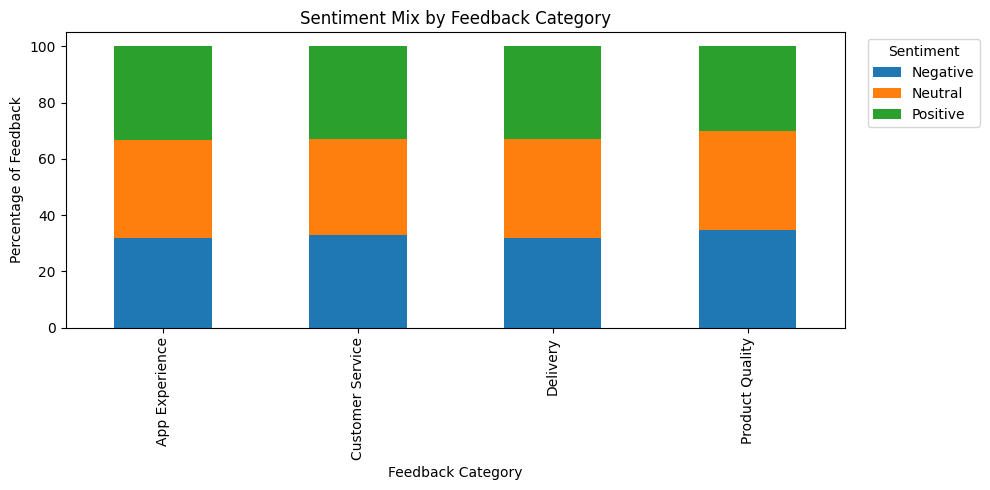

In [14]:
category_sentiment.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Sentiment Mix by Feedback Category")
plt.xlabel("Feedback Category")
plt.ylabel("Percentage of Feedback")
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [16]:
import pandas as pd

# Ensure delivery_clean is defined by reading the CSV and applying clean-up
delivery_data = pd.read_csv("blinkit_delivery_performance.csv")
delivery_clean = delivery_data.copy()
delivery_clean["reasons_if_delayed"] = delivery_clean["reasons_if_delayed"].fillna("Not Provided / Not Applicable")

feedback_delivery = feedback_clean.merge(
    delivery_clean[[
        "order_id",
        "delivery_status",
        "delivery_time_minutes",
        "promised_time",
        "actual_time"
    ]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Feedback rows:", len(feedback_clean))
print("Rows after merge:", len(feedback_delivery))
print("Missing delivery matches:", feedback_delivery["delivery_status"].isna().sum())

display(feedback_delivery.head())

Feedback rows: 5000
Rows after merge: 5000
Missing delivery matches: 0


,feedback_id,order_id,customer_id,rating,feedback_text,feedback_category,sentiment,feedback_date,delivery_status,delivery_time_minutes,promised_time,actual_time
0,2234710,1961864118,30065862,4,"It was okay, nothing special.",Delivery,Neutral,2024-07-17,On Time,-5.0,2024-07-17 08:52:01,2024-07-17 08:47:01
1,5450964,1549769649,9573071,3,The order was incorrect.,App Experience,Negative,2024-05-28,On Time,2.0,2024-05-28 13:25:29,2024-05-28 13:27:29
2,482108,9185164487,45477575,3,"It was okay, nothing special.",App Experience,Neutral,2024-09-23,On Time,4.0,2024-09-23 13:25:12,2024-09-23 13:29:12
3,4823104,9644738826,88067569,4,The product met my expectations.,App Experience,Neutral,2023-11-24,On Time,-1.0,2023-11-24 16:34:56,2023-11-24 16:33:56
4,3537464,5427684290,83298567,3,Product was damaged during delivery.,Delivery,Negative,2023-11-20,On Time,1.0,2023-11-20 05:17:39,2023-11-20 05:18:39


In [17]:
delivery_rating_summary = (
    feedback_delivery
    .groupby("delivery_status")
    .agg(
        feedback_count=("feedback_id", "count"),
        average_rating=("rating", "mean")
    )
    .sort_values("average_rating")
)

display(delivery_rating_summary)

,feedback_count,average_rating
delivery_status,,
Significantly Delayed,493,3.326572
On Time,3470,3.332565
Slightly Delayed,1037,3.392478


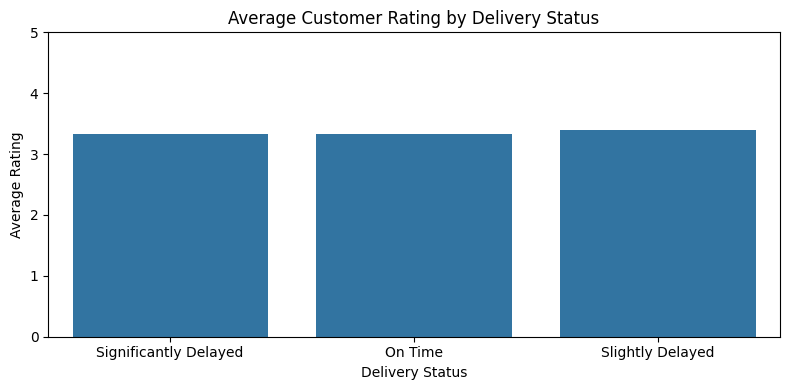

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.barplot(
    data=delivery_rating_summary.reset_index(),
    x="delivery_status",
    y="average_rating"
)

plt.title("Average Customer Rating by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

In [19]:
delivery_check = delivery_clean.copy()

delivery_check["promised_time"] = pd.to_datetime(
    delivery_check["promised_time"], errors="coerce"
)
delivery_check["actual_time"] = pd.to_datetime(
    delivery_check["actual_time"], errors="coerce"
)

delivery_check["calculated_delay_minutes"] = (
    delivery_check["actual_time"] - delivery_check["promised_time"]
).dt.total_seconds() / 60

display(
    delivery_check[
        ["delivery_time_minutes", "calculated_delay_minutes"]
    ].head(10)
)

print(
    "Exact matches:",
    (
        delivery_check["delivery_time_minutes"]
        == delivery_check["calculated_delay_minutes"]
    ).sum()
)

,delivery_time_minutes,calculated_delay_minutes
0,-5.0,-5.0
1,2.0,2.0
2,4.0,4.0
3,-1.0,-1.0
4,1.0,1.0
5,-1.0,-1.0
6,1.0,1.0
7,2.0,2.0
8,3.0,3.0
9,7.0,7.0


Exact matches: 5000


In [20]:
delivery_check["delivery_status"].value_counts()


,count
delivery_status,
On Time,3470
Slightly Delayed,1037
Significantly Delayed,493


In [21]:
delivery_metrics = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "On-Time Deliveries",
        "Slightly Delayed Deliveries",
        "Significantly Delayed Deliveries",
        "Average Delay (minutes)",
        "Median Delay (minutes)",
        "Maximum Delay (minutes)",
        "Early Deliveries"
    ],
    "Value": [
        len(delivery_check),
        (delivery_check["delivery_status"] == "On Time").sum(),
        (delivery_check["delivery_status"] == "Slightly Delayed").sum(),
        (delivery_check["delivery_status"] == "Significantly Delayed").sum(),
        delivery_check["calculated_delay_minutes"].mean(),
        delivery_check["calculated_delay_minutes"].median(),
        delivery_check["calculated_delay_minutes"].max(),
        (delivery_check["calculated_delay_minutes"] < 0).sum()
    ]
})

display(delivery_metrics)

,Metric,Value
0,Total Orders,5000.000
1,On-Time Deliveries,3470.000
2,Slightly Delayed Deliveries,1037.000
3,Significantly Delayed Deliveries,493.000
4,Average Delay (minutes),4.443
5,Median Delay (minutes),2.000
6,Maximum Delay (minutes),30.000
7,Early Deliveries,1563.000


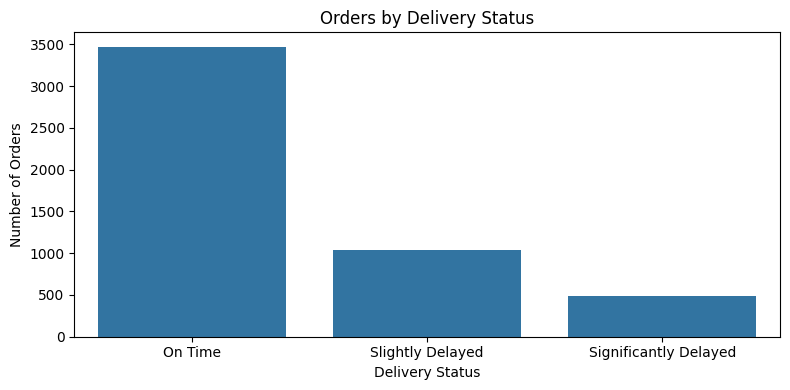

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.countplot(
    data=delivery_check,
    x="delivery_status",
    order=["On Time", "Slightly Delayed", "Significantly Delayed"]
)
plt.title("Orders by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

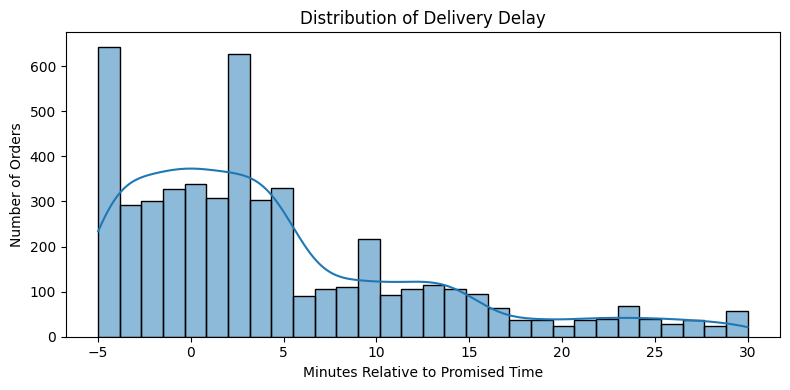

In [23]:
plt.figure(figsize=(8, 4))
sns.histplot(
    data=delivery_check,
    x="calculated_delay_minutes",
    bins=30,
    kde=True
)
plt.title("Distribution of Delivery Delay")
plt.xlabel("Minutes Relative to Promised Time")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [24]:
delayed_orders = delivery_check[
    delivery_check["delivery_status"] != "On Time"
].copy()

delay_reason_summary = (
    delayed_orders["reasons_if_delayed"]
    .value_counts(dropna=False)
    .reset_index()
)

delay_reason_summary.columns = ["Delay Reason", "Order Count"]

display(delay_reason_summary)

,Delay Reason,Order Count
0,Traffic,1530


In [26]:
import pandas as pd

# Load datasets directly from files
inventory = pd.read_csv("blinkit_inventory.csv")
inventory_new = pd.read_csv("blinkit_inventoryNew.csv")

# Standard inventory file: dates like 17-03-2023
inventory_clean = inventory.copy()

inventory_clean["date"] = pd.to_datetime(
    inventory_clean["date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# New inventory file: dates like Mar-23
inventory_new_clean = inventory_new.copy()

inventory_new_clean["date"] = pd.to_datetime(
    inventory_new_clean["date"],
    format="%b-%y",
    errors="coerce"
)

print("Inventory rows:", len(inventory_clean))
print("InventoryNew rows before deduplication:", len(inventory_new_clean))
print("Exact duplicate rows:", inventory_new_clean.duplicated().sum())
print("Inventory date conversion failures:", inventory_clean["date"].isna().sum())
print("InventoryNew date conversion failures:", inventory_new_clean["date"].isna().sum())

Inventory rows: 75172
InventoryNew rows before deduplication: 18105
Exact duplicate rows: 7359
Inventory date conversion failures: 0
InventoryNew date conversion failures: 0


In [27]:
inventory_new_clean[
    inventory_new_clean.duplicated(keep=False)
].sort_values(["product_id", "date"]).head(20)

,product_id,date,stock_received,damaged_stock
858,4452,2023-04-01,1,0
1433,4452,2023-04-01,1,0
1908,4452,2023-05-01,1,0
2722,4452,2023-05-01,1,0
3008,4452,2023-06-01,1,0
3346,4452,2023-06-01,1,0
3916,4452,2023-07-01,1,0
4385,4452,2023-07-01,1,0
5071,4452,2023-08-01,1,0
5362,4452,2023-08-01,1,0


In [28]:
inventory_new_clean = inventory_new_clean.drop_duplicates().copy()

print("Rows after removing exact duplicates:", len(inventory_new_clean))
print("Remaining exact duplicates:", inventory_new_clean.duplicated().sum())

Rows after removing exact duplicates: 10746
Remaining exact duplicates: 0


In [29]:
inventory_summary = pd.DataFrame({
    "Metric": [
        "Unique products",
        "Total stock received",
        "Total damaged stock",
        "Damage rate (%)",
        "Date range"
    ],
    "Value": [
        inventory_new_clean["product_id"].nunique(),
        inventory_new_clean["stock_received"].sum(),
        inventory_new_clean["damaged_stock"].sum(),
        (
            inventory_new_clean["damaged_stock"].sum()
            / inventory_new_clean["stock_received"].sum()
            * 100
        ),
        f'{inventory_new_clean["date"].min().date()} to '
        f'{inventory_new_clean["date"].max().date()}'
    ]
})

display(inventory_summary)

,Metric,Value
0,Unique products,268
1,Total stock received,18485
2,Total damaged stock,1022
3,Damage rate (%),5.528807
4,Date range,2023-03-01 to 2024-11-01


In [30]:
monthly_inventory = (
    inventory_new_clean
    .groupby("date")
    .agg(
        stock_received=("stock_received", "sum"),
        damaged_stock=("damaged_stock", "sum")
    )
    .sort_index()
)

monthly_inventory["damage_rate_pct"] = (
    monthly_inventory["damaged_stock"]
    / monthly_inventory["stock_received"]
    * 100
)

display(monthly_inventory)

,stock_received,damaged_stock,damage_rate_pct
date,,,
2023-03-01,1068,17,1.591760
2023-04-01,766,0,0.000000
2023-05-01,803,31,3.860523
2023-06-01,619,151,24.394184
2023-07-01,293,25,8.532423
2023-08-01,451,226,50.110865
2023-09-01,983,0,0.000000
2023-10-01,1254,273,21.770335
2023-11-01,1292,36,2.786378


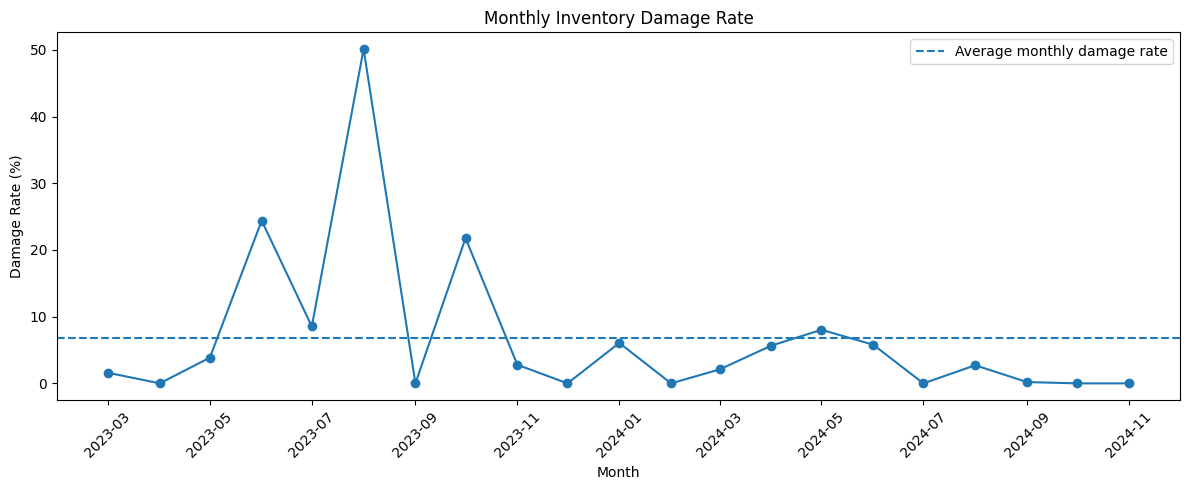

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_inventory.index,
    monthly_inventory["damage_rate_pct"],
    marker="o"
)

plt.axhline(
    monthly_inventory["damage_rate_pct"].mean(),
    linestyle="--",
    label="Average monthly damage rate"
)

plt.title("Monthly Inventory Damage Rate")
plt.xlabel("Month")
plt.ylabel("Damage Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
product_damage = (
    inventory_new_clean
    .groupby("product_id")
    .agg(
        stock_received=("stock_received", "sum"),
        damaged_stock=("damaged_stock", "sum")
    )
)

product_damage["damage_rate_pct"] = (
    product_damage["damaged_stock"]
    / product_damage["stock_received"]
    * 100
)

top_damaged_products = (
    product_damage
    .sort_values("damaged_stock", ascending=False)
    .head(10)
)

display(top_damaged_products)

,stock_received,damaged_stock,damage_rate_pct
product_id,,,
124290,78,13,16.666667
661577,78,12,15.384615
317242,80,10,12.500000
91670,73,9,12.328767
461804,77,8,10.389610
433521,71,8,11.267606
398340,60,8,13.333333
647462,68,8,11.764706
897083,53,7,13.207547


In [34]:
import pandas as pd

marketing = pd.read_csv("blinkit_marketing_performance.csv")
marketing_clean = marketing.copy()

In [35]:
print("Shape:", marketing_clean.shape)
print("\nColumns:", marketing_clean.columns.tolist())
print("\nMissing values:")
print(marketing_clean.isnull().sum())

display(marketing_clean.head())

Shape: (5400, 11)

Columns: ['campaign_id', 'campaign_name', 'date', 'target_audience', 'channel', 'impressions', 'clicks', 'conversions', 'spend', 'revenue_generated', 'roas']

Missing values:
campaign_id          0
campaign_name        0
date                 0
target_audience      0
channel              0
impressions          0
clicks               0
conversions          0
spend                0
revenue_generated    0
roas                 0
dtype: int64


,campaign_id,campaign_name,date,target_audience,channel,impressions,clicks,conversions,spend,revenue_generated,roas
0,548299,New User Discount,2024-11-05,Premium,App,3130,163,78,1431.85,4777.75,3.60
1,390914,Weekend Special,2024-11-05,Inactive,App,3925,494,45,4506.34,6238.11,2.98
2,834385,Festival Offer,2024-11-05,Inactive,Email,7012,370,78,4524.23,2621.00,2.95
3,241523,Flash Sale,2024-11-05,Inactive,SMS,1115,579,86,3622.79,2955.00,2.84
4,595111,Membership Drive,2024-11-05,New Users,Email,7172,795,54,2888.99,8951.81,2.22


In [36]:
marketing_clean["date"] = pd.to_datetime(
    marketing_clean["date"],
    errors="coerce"
)

marketing_clean["CTR_pct"] = (
    marketing_clean["clicks"]
    / marketing_clean["impressions"]
    * 100
)

marketing_clean["conversion_rate_pct"] = (
    marketing_clean["conversions"]
    / marketing_clean["clicks"]
    * 100
)

marketing_clean["ROAS"] = (
    marketing_clean["revenue_generated"]
    / marketing_clean["spend"]
)

display(marketing_clean[
    ["campaign_name", "channel", "impressions", "clicks",
     "conversions", "spend", "revenue_generated",
     "CTR_pct", "conversion_rate_pct", "ROAS"]
].head(10))

,campaign_name,channel,impressions,clicks,conversions,spend,revenue_generated,CTR_pct,conversion_rate_pct,ROAS
0,New User Discount,App,3130,163,78,1431.85,4777.75,5.207668,47.852761,3.336767
1,Weekend Special,App,3925,494,45,4506.34,6238.11,12.585987,9.109312,1.384296
2,Festival Offer,Email,7012,370,78,4524.23,2621.00,5.276669,21.081081,0.579325
3,Flash Sale,SMS,1115,579,86,3622.79,2955.00,51.928251,14.853195,0.815670
4,Membership Drive,Email,7172,795,54,2888.99,8951.81,11.084774,6.792453,3.098595
5,Category Promotion,App,4333,421,40,2714.78,6697.88,9.716132,9.501188,2.467191
6,App Push Notification,Email,4752,937,21,3584.76,9152.99,19.718013,2.241195,2.553306
7,Email Campaign,Social Media,1559,418,68,1457.88,2156.09,26.812059,16.267943,1.478921
8,Referral Program,SMS,3838,911,45,4808.64,8074.17,23.736321,4.939627,1.679096
9,New User Discount,SMS,6289,834,14,3746.35,4474.02,13.261250,1.678657,1.194234


In [37]:
channel_summary = (
    marketing_clean
    .groupby("channel")
    .agg(
        campaigns=("campaign_id", "nunique"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        conversions=("conversions", "sum"),
        spend=("spend", "sum"),
        revenue=("revenue_generated", "sum")
    )
)

channel_summary["CTR_pct"] = (
    channel_summary["clicks"]
    / channel_summary["impressions"]
    * 100
)

channel_summary["conversion_rate_pct"] = (
    channel_summary["conversions"]
    / channel_summary["clicks"]
    * 100
)

channel_summary["ROAS"] = (
    channel_summary["revenue"]
    / channel_summary["spend"]
)

display(channel_summary.sort_values("ROAS", ascending=False))

,campaigns,impressions,clicks,conversions,spend,revenue,CTR_pct,conversion_rate_pct,ROAS
channel,,,,,,,,,
Email,1343,7275694,756057,74671,3997488.04,8189331.58,10.391545,9.876372,2.048619
SMS,1340,7367010,744274,73235,3998607.54,7938649.32,10.102796,9.839790,1.985353
Social Media,1343,7281244,738839,74940,4110363.91,7990415.98,10.147153,10.142940,1.943968
App,1374,7563662,734975,75192,4213378.75,8075010.49,9.717185,10.230552,1.916517


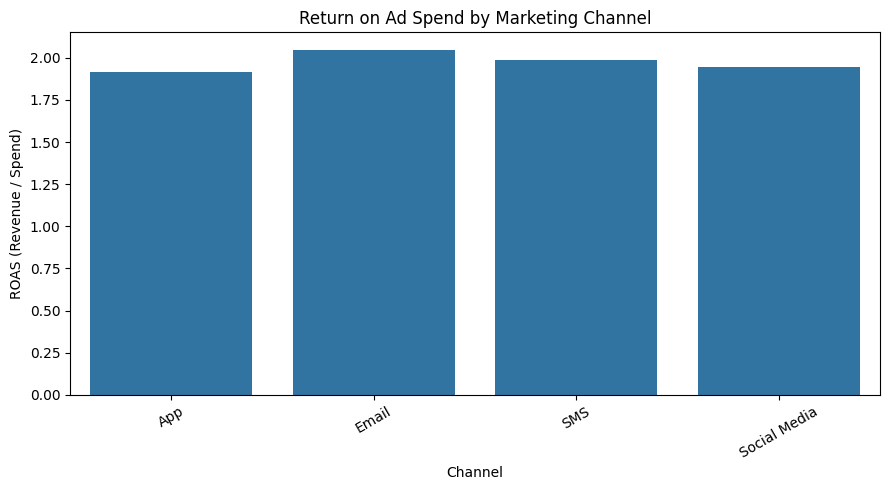

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

channel_plot = channel_summary.reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=channel_plot,
    x="channel",
    y="ROAS"
)

plt.title("Return on Ad Spend by Marketing Channel")
plt.xlabel("Channel")
plt.ylabel("ROAS (Revenue / Spend)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [8]:
import pandas as pd
import os

# Define the base directory path
base_dir = "/content/" if os.path.exists("/content/") else ""

# Helper to build the correct path
def get_path(filename):
    full_path = os.path.join(base_dir, filename)
    if os.path.exists(full_path):
        return full_path
    return filename

# Re-load and prepare datasets directly
feedback_clean = pd.read_csv(get_path("blinkit_customer_feedback.csv")).drop_duplicates()
feedback_clean["rating"] = pd.to_numeric(feedback_clean["rating"], errors="coerce")

delivery_clean = pd.read_csv(get_path("blinkit_delivery_performance.csv")).drop_duplicates()
delivery_clean["reasons_if_delayed"] = delivery_clean["reasons_if_delayed"].fillna("Not Provided / Not Applicable")

inventory_new_clean = pd.read_csv(get_path("blinkit_inventoryNew.csv")).drop_duplicates()
inventory_new_clean["date"] = pd.to_datetime(inventory_new_clean["date"], format="%b-%y", errors="coerce")

marketing_clean = pd.read_csv(get_path("blinkit_marketing_performance.csv")).drop_duplicates()

# 1. Customer Feedback Summary
sentiment_summary = (
    feedback_clean
    .groupby("sentiment")
    .agg(
        feedback_count=("feedback_id", "count"),
        average_rating=("rating", "mean")
    )
    .sort_values("feedback_count", ascending=False)
)

category_sentiment = pd.crosstab(
    feedback_clean["feedback_category"],
    feedback_clean["sentiment"],
    normalize="index"
) * 100

print("=== CUSTOMER FEEDBACK ===")
display(sentiment_summary)
display(category_sentiment)

# 2. Delivery Metrics
delivery_metrics = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "On-Time Deliveries",
        "Slightly Delayed Deliveries",
        "Significantly Delayed Deliveries",
        "Average Delay (minutes)",
        "Median Delay (minutes)",
        "Maximum Delay (minutes)",
        "Early Deliveries"
    ],
    "Value": [
        len(delivery_clean),
        (delivery_clean["delivery_status"] == "On Time").sum(),
        (delivery_clean["delivery_status"] == "Slightly Delayed").sum(),
        (delivery_clean["delivery_status"] == "Significantly Delayed").sum(),
        (pd.to_datetime(delivery_clean["actual_time"], errors="coerce") - pd.to_datetime(delivery_clean["promised_time"], errors="coerce")).dt.total_seconds().mean() / 60,
        (pd.to_datetime(delivery_clean["actual_time"], errors="coerce") - pd.to_datetime(delivery_clean["promised_time"], errors="coerce")).dt.total_seconds().median() / 60,
        (pd.to_datetime(delivery_clean["actual_time"], errors="coerce") - pd.to_datetime(delivery_clean["promised_time"], errors="coerce")).dt.total_seconds().max() / 60,
        ((pd.to_datetime(delivery_clean["actual_time"], errors="coerce") - pd.to_datetime(delivery_clean["promised_time"], errors="coerce")).dt.total_seconds() / 60 < 0).sum()
    ]
})

print("\n=== DELIVERY PERFORMANCE ===")
display(delivery_metrics)

# 3. Inventory Summary
inventory_summary = pd.DataFrame({
    "Metric": [
        "Unique products",
        "Total stock received",
        "Total damaged stock",
        "Damage rate (%)",
        "Date range"
    ],
    "Value": [
        inventory_new_clean["product_id"].nunique(),
        inventory_new_clean["stock_received"].sum(),
        inventory_new_clean["damaged_stock"].sum(),
        (inventory_new_clean["damaged_stock"].sum() / inventory_new_clean["stock_received"].sum() * 100),
        f'{inventory_new_clean["date"].min().date()} to {inventory_new_clean["date"].max().date()}'
    ]
})

product_damage = (
    inventory_new_clean
    .groupby("product_id")
    .agg(
        stock_received=("stock_received", "sum"),
        damaged_stock=("damaged_stock", "sum")
    )
)
product_damage["damage_rate_pct"] = (product_damage["damaged_stock"] / product_damage["stock_received"] * 100)
top_damaged_products = product_damage.sort_values("damaged_stock", ascending=False).head(10)

print("\n=== INVENTORY ===")
display(inventory_summary)
display(top_damaged_products)

# 4. Marketing Summary
channel_summary = (
    marketing_clean
    .groupby("channel")
    .agg(
        campaigns=("campaign_id", "nunique"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        conversions=("conversions", "sum"),
        spend=("spend", "sum"),
        revenue=("revenue_generated", "sum")
    )
)
channel_summary["CTR_pct"] = (channel_summary["clicks"] / channel_summary["impressions"] * 100)
channel_summary["conversion_rate_pct"] = (channel_summary["conversions"] / channel_summary["clicks"] * 100)
channel_summary["ROAS"] = (channel_summary["revenue"] / channel_summary["spend"])

print("\n=== MARKETING ===")
display(channel_summary.sort_values("ROAS", ascending=False))

=== CUSTOMER FEEDBACK ===


,feedback_count,average_rating
sentiment,,
Neutral,1738,3.520138
Negative,1642,2.014616
Positive,1620,4.503704


sentiment,Negative,Neutral,Positive
feedback_category,,,
App Experience,31.986810,34.707337,33.305853
Customer Service,32.938389,34.044234,33.017378
Delivery,31.864673,35.090480,33.044847
Product Quality,34.560000,35.200000,30.240000



=== DELIVERY PERFORMANCE ===


,Metric,Value
0,Total Orders,5000.000
1,On-Time Deliveries,3470.000
2,Slightly Delayed Deliveries,1037.000
3,Significantly Delayed Deliveries,493.000
4,Average Delay (minutes),4.443
5,Median Delay (minutes),2.000
6,Maximum Delay (minutes),30.000
7,Early Deliveries,1563.000



=== INVENTORY ===


,Metric,Value
0,Unique products,268
1,Total stock received,18485
2,Total damaged stock,1022
3,Damage rate (%),5.528807
4,Date range,2023-03-01 to 2024-11-01


,stock_received,damaged_stock,damage_rate_pct
product_id,,,
124290,78,13,16.666667
661577,78,12,15.384615
317242,80,10,12.500000
91670,73,9,12.328767
461804,77,8,10.389610
433521,71,8,11.267606
398340,60,8,13.333333
647462,68,8,11.764706
897083,53,7,13.207547



=== MARKETING ===


,campaigns,impressions,clicks,conversions,spend,revenue,CTR_pct,conversion_rate_pct,ROAS
channel,,,,,,,,,
Email,1343,7275694,756057,74671,3997488.04,8189331.58,10.391545,9.876372,2.048619
SMS,1340,7367010,744274,73235,3998607.54,7938649.32,10.102796,9.839790,1.985353
Social Media,1343,7281244,738839,74940,4110363.91,7990415.98,10.147153,10.142940,1.943968
App,1374,7563662,734975,75192,4213378.75,8075010.49,9.717185,10.230552,1.916517


In [6]:
# Export key summary tables
sentiment_summary.to_csv("sentiment_summary.csv")
delivery_metrics.to_csv("delivery_metrics.csv", index=False)
inventory_summary.to_csv("inventory_summary.csv", index=False)
top_damaged_products.to_csv("top_damaged_products.csv")
channel_summary.to_csv("channel_summary.csv")

print("Summary tables exported.")

Summary tables exported.


In [10]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display
import os

# Define the base directory path
base_dir = "/content/" if os.path.exists("/content/") else ""

def get_path(filename):
    full_path = os.path.join(base_dir, filename)
    if os.path.exists(full_path):
        return full_path
    return filename

# ---------- Recalculate summaries from your existing data ----------

# Load and clean baseline datasets directly to ensure resilience against runtime resets
feedback_clean = pd.read_csv(get_path("blinkit_customer_feedback.csv")).drop_duplicates()
feedback_clean["rating"] = pd.to_numeric(feedback_clean["rating"], errors="coerce")

delivery_check = pd.read_csv(get_path("blinkit_delivery_performance.csv")).drop_duplicates()
delivery_check["promised_time"] = pd.to_datetime(delivery_check["promised_time"], errors="coerce")
delivery_check["actual_time"] = pd.to_datetime(delivery_check["actual_time"], errors="coerce")

inventory_new_clean = pd.read_csv(get_path("blinkit_inventoryNew.csv")).drop_duplicates()
inventory_new_clean["date"] = pd.to_datetime(inventory_new_clean["date"], format="%b-%y", errors="coerce")

marketing_clean = pd.read_csv(get_path("blinkit_marketing_performance.csv")).drop_duplicates()

# Feedback
sentiment_summary = (
    feedback_clean.groupby("sentiment")
    .agg(
        feedback_count=("feedback_id", "count"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

category_sentiment = (
    pd.crosstab(
        feedback_clean["feedback_category"],
        feedback_clean["sentiment"],
        normalize="index"
    ) * 100
).reset_index()

# Delivery
delivery_status_summary = (
    delivery_check.groupby("delivery_status")
    .agg(order_count=("order_id", "count"))
    .reset_index()
)

delivery_check["calculated_delay_minutes"] = (
    delivery_check["actual_time"] - delivery_check["promised_time"]
).dt.total_seconds() / 60

# Inventory
monthly_inventory = (
    inventory_new_clean.groupby("date")
    .agg(
        stock_received=("stock_received", "sum"),
        damaged_stock=("damaged_stock", "sum")
    )
    .reset_index()
    .sort_values("date")
)

monthly_inventory["damage_rate_pct"] = (
    monthly_inventory["damaged_stock"]
    / monthly_inventory["stock_received"] * 100
)

product_damage = (
    inventory_new_clean.groupby("product_id")
    .agg(
        stock_received=("stock_received", "sum"),
        damaged_stock=("damaged_stock", "sum")
    )
    .reset_index()
)

product_damage["damage_rate_pct"] = (
    product_damage["damaged_stock"]
    / product_damage["stock_received"] * 100
)

top_products = product_damage.nlargest(10, "damaged_stock")

# Marketing
marketing_clean["CTR_pct"] = (
    marketing_clean["clicks"] / marketing_clean["impressions"] * 100
)

marketing_clean["conversion_rate_pct"] = (
    marketing_clean["conversions"] / marketing_clean["clicks"] * 100
)

marketing_clean["ROAS"] = (
    marketing_clean["revenue_generated"] / marketing_clean["spend"]
)

channel_summary = (
    marketing_clean.groupby("channel")
    .agg(
        campaigns=("campaign_id", "nunique"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        conversions=("conversions", "sum"),
        spend=("spend", "sum"),
        revenue=("revenue_generated", "sum")
    )
    .reset_index()
)

channel_summary["CTR_pct"] = (
    channel_summary["clicks"] / channel_summary["impressions"] * 100
)

channel_summary["conversion_rate_pct"] = (
    channel_summary["conversions"] / channel_summary["clicks"] * 100
)

channel_summary["ROAS"] = (
    channel_summary["revenue"] / channel_summary["spend"]
)

# ---------- Dashboard ----------

fig = make_subplots(
    rows=3, cols=2,
    subplot_titles=(
        "Feedback Sentiment",
        "Delivery Status",
        "Monthly Inventory Damage Rate",
        "Top 10 Products by Damaged Stock",
        "Marketing ROAS by Channel",
        "Average Rating by Sentiment"
    ),
    specs=[
        [{"type": "bar"}, {"type": "bar"}],
        [{"type": "scatter"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "bar"}]
    ],
    vertical_spacing=0.13,
    horizontal_spacing=0.10
)

# Sentiment counts
fig.add_trace(
    go.Bar(
        x=sentiment_summary["sentiment"],
        y=sentiment_summary["feedback_count"],
        name="Feedback count",
        marker_color="#2E8B57"
    ),
    row=1, col=1
)

# Delivery status
fig.add_trace(
    go.Bar(
        x=delivery_status_summary["delivery_status"],
        y=delivery_status_summary["order_count"],
        name="Orders",
        marker_color="#F4B400"
    ),
    row=1, col=2
)

# Monthly damage trend
fig.add_trace(
    go.Scatter(
        x=monthly_inventory["date"],
        y=monthly_inventory["damage_rate_pct"],
        mode="lines+markers",
        name="Damage rate (%)",
        line=dict(color="#2E8B57", width=3)
    ),
    row=2, col=1
)

# Top damaged products
fig.add_trace(
    go.Bar(
        x=top_products["product_id"].astype(str),
        y=top_products["damaged_stock"],
        name="Damaged stock",
        marker_color="#E76F51"
    ),
    row=2, col=2
)

# Marketing ROAS
fig.add_trace(
    go.Bar(
        x=channel_summary["channel"],
        y=channel_summary["ROAS"],
        name="ROAS",
        marker_color="#457B9D"
    ),
    row=3, col=1
)

# Rating by sentiment
fig.add_trace(
    go.Bar(
        x=sentiment_summary["sentiment"],
        y=sentiment_summary["average_rating"],
        name="Average rating",
        marker_color="#8E7CC3"
    ),
    row=3, col=2
)

fig.update_layout(
    title="Blinkit-Themed Business Analytics Dashboard",
    height=1100,
    width=1200,
    template="plotly_white",
    showlegend=False
)

fig.update_yaxes(title_text="Feedback records", row=1, col=1)
fig.update_yaxes(title_text="Orders", row=1, col=2)
fig.update_yaxes(title_text="Damage rate (%)", row=2, col=1)
fig.update_yaxes(title_text="Damaged units", row=2, col=2)
fig.update_yaxes(title_text="ROAS", row=3, col=1)
fig.update_yaxes(title_text="Rating (out of 5)", range=[0, 5], row=3, col=2)

fig.show()

# Save an interactive HTML version
fig.write_html("blinkit_business_analytics_dashboard.html")

print("Dashboard created and saved as blinkit_business_analytics_dashboard.html")

Dashboard created and saved as blinkit_business_analytics_dashboard.html


In [11]:
from google.colab import files

files.download("blinkit_business_analytics_dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# ---------- Recalculate core metrics ----------

total_feedback = len(feedback_clean)
avg_rating = feedback_clean["rating"].mean()
positive_pct = (feedback_clean["sentiment"] == "Positive").mean() * 100

total_orders = len(delivery_check)
on_time_pct = (delivery_check["delivery_status"] == "On Time").mean() * 100
avg_delay = delivery_check["calculated_delay_minutes"].mean()

total_stock = inventory_new_clean["stock_received"].sum()
total_damaged = inventory_new_clean["damaged_stock"].sum()
damage_rate = total_damaged / total_stock * 100

total_spend = marketing_clean["spend"].sum()
total_revenue = marketing_clean["revenue_generated"].sum()
overall_roas = total_revenue / total_spend

# ---------- Prepare chart summaries ----------

sentiment_counts = feedback_clean["sentiment"].value_counts().reindex(
    ["Positive", "Neutral", "Negative"], fill_value=0
)

delivery_counts = delivery_check["delivery_status"].value_counts().reindex(
    ["On Time", "Slightly Delayed", "Significantly Delayed"], fill_value=0
)

monthly_inventory = (
    inventory_new_clean.groupby("date")
    .agg(
        stock_received=("stock_received", "sum"),
        damaged_stock=("damaged_stock", "sum")
    )
    .reset_index()
    .sort_values("date")
)
monthly_inventory["damage_rate_pct"] = (
    monthly_inventory["damaged_stock"] / monthly_inventory["stock_received"] * 100
)

product_damage = (
    inventory_new_clean.groupby("product_id")
    .agg(damaged_stock=("damaged_stock", "sum"))
    .reset_index()
    .nlargest(10, "damaged_stock")
    .sort_values("damaged_stock")
)

channel_summary = (
    marketing_clean.groupby("channel")
    .agg(
        clicks=("clicks", "sum"),
        conversions=("conversions", "sum"),
        spend=("spend", "sum"),
        revenue=("revenue_generated", "sum"),
        impressions=("impressions", "sum")
    )
    .reset_index()
)
channel_summary["ROAS"] = channel_summary["revenue"] / channel_summary["spend"]
channel_summary["CTR_pct"] = channel_summary["clicks"] / channel_summary["impressions" ] * 100
channel_summary["conversion_rate_pct"] = (
    channel_summary["conversions"] / channel_summary["clicks"] * 100
)

# ---------- Build polished dashboard ----------

green = "#16803C"
dark = "#12372A"
yellow = "#F5C542"
red = "#D9534F"
blue = "#3478A3"

fig = make_subplots(
    rows=3, cols=2,
    specs=[
        [{"type": "domain"}, {"type": "domain"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],
    subplot_titles=(
        "Customer Sentiment Mix",
        "Delivery Reliability",
        "Monthly Inventory Damage Rate",
        "Top Products by Damaged Units",
        "Marketing ROAS by Channel",
        "Marketing CTR vs Conversion Rate"
    ),
    vertical_spacing=0.14,
    horizontal_spacing=0.12
)

# Sentiment donut
fig.add_trace(
    go.Pie(
        labels=sentiment_counts.index,
        values=sentiment_counts.values,
        hole=0.62,
        marker_colors=[green, yellow, red],
        textinfo="label+percent",
        name="Sentiment"
    ),
    row=1, col=1
)

# Delivery donut
fig.add_trace(
    go.Pie(
        labels=delivery_counts.index,
        values=delivery_counts.values,
        hole=0.62,
        marker_colors=[green, yellow, red],
        textinfo="label+percent",
        name="Delivery"
    ),
    row=1, col=2
)

# Inventory trend
fig.add_trace(
    go.Scatter(
        x=monthly_inventory["date"],
        y=monthly_inventory["damage_rate_pct"],
        mode="lines+markers",
        line=dict(color=green, width=3),
        marker=dict(size=7),
        name="Damage rate"
    ),
    row=2, col=1
)

# Add specific horizontal line shape on Row 2, Col 1 subplot to avoid global layout issues
fig.add_shape(
    type="line",
    xref="x3", yref="y3",
    x0=monthly_inventory["date"].min(),
    x1=monthly_inventory["date"].max(),
    y0=damage_rate,
    y1=damage_rate,
    line=dict(color=yellow, width=2, dash="dash"),
    row=2, col=1
)

fig.add_annotation(
    xref="x3", yref="y3",
    x=monthly_inventory["date"].median(),
    y=damage_rate,
    text=f"Overall {damage_rate:.2f}%",
    showarrow=False,
    yshift=10,
    font=dict(color=dark),
    row=2, col=1
)

# Top damaged products
fig.add_trace(
    go.Bar(
        x=product_damage["damaged_stock"],
        y=product_damage["product_id"].astype(str),
        orientation="h",
        marker_color=red,
        name="Damaged units"
    ),
    row=2, col=2
)

# Marketing ROAS
fig.add_trace(
    go.Bar(
        x=channel_summary["channel"],
        y=channel_summary["ROAS"],
        marker_color=blue,
        text=channel_summary["ROAS"].round(2),
        textposition="outside",
        name="ROAS"
    ),
    row=3, col=1
)

# CTR and conversion rate comparison
fig.add_trace(
    go.Bar(
        x=channel_summary["channel"],
        y=channel_summary["CTR_pct"],
        marker_color=green,
        name="CTR (%)"
    ),
    row=3, col=2
)

fig.add_trace(
    go.Bar(
        x=channel_summary["channel"],
        y=channel_summary["conversion_rate_pct"],
        marker_color=yellow,
        name="Conversion rate (%)"
    ),
    row=3, col=2
)

# ---------- Styling ----------

fig.update_layout(
    title=dict(
        text="Business Analytics Overview<br><sup>Customer • Delivery • Inventory • Marketing</sup>",
        x=0.03,
        xanchor="left",
        font=dict(size=28, color=dark)
    ),
    height=1250,
    width=1450,
    template="plotly_white",
    paper_bgcolor="#F5F8F6",
    plot_bgcolor="#FFFFFF",
    font=dict(family="Arial", size=13, color=dark),
    margin=dict(l=55, r=55, t=120, b=60),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.08,
        xanchor="center",
        x=0.5
    ),
    barmode="group"
)

fig.update_xaxes(showgrid=False, linecolor="#D5DED9")
fig.update_yaxes(gridcolor="#E8EEEA", zeroline=False)

# KPI cards across top using annotations
kpis = [
    ("FEEDBACK", f"{total_feedback:,}", "records"),
    ("AVERAGE RATING", f"{avg_rating:.2f}/5", "customer rating"),
    ("ON-TIME DELIVERY", f"{on_time_pct:.1f}%", "of orders"),
    ("INVENTORY DAMAGE", f"{damage_rate:.2f}%", "of stock received"),
    ("MARKETING ROAS", f"{overall_roas:.2f}x", "revenue / spend")
]

for i, (label, value, subtitle) in enumerate(kpis):
    x0 = 0.02 + i * 0.195
    x1 = x0 + 0.18
    fig.add_shape(
        type="rect",
        xref="paper", yref="paper",
        x0=x0, x1=x1, y0=1.02, y1=1.14,
        line=dict(color="#DCE7E0", width=1),
        fillcolor="#FFFFFF"
    )
    fig.add_annotation(
        x=(x0+x1)/2, y=1.115,
        xref="paper", yref="paper",
        text=f"<b>{label}</b>",
        showarrow=False,
        font=dict(size=11, color="#6A7D73")
    )
    fig.add_annotation(
        x=(x0+x1)/2, y=1.075,
        xref="paper", yref="paper",
        text=f"<b>{value}</b>",
        showarrow=False,
        font=dict(size=22, color=dark)
    )
    fig.add_annotation(
        x=(x0+x1)/2, y=1.035,
        xref="paper", yref="paper",
        text=subtitle,
        showarrow=False,
        font=dict(size=10, color="#6A7D73")
    )

fig.show()
fig.write_html("blinkit_executive_dashboard.html")

print("Saved: blinkit_executive_dashboard.html")

Saved: blinkit_executive_dashboard.html


```markdown
## Live Interactive Business Analytics Dashboard

This dashboard leverages dynamic HTML components inside Colab using `ipywidgets` and `plotly` to build a beautifully formatted interface. You can use the drop-down selectors and range sliders to filter your data in real-time across Customer, Delivery, Inventory, and Marketing metrics.
```

In [16]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
import os

# Configure styling variables
green_color = "#16803C"
dark_color = "#12372A"
yellow_color = "#F5C542"
red_color = "#D9534F"
blue_color = "#3478A3"

# Robust base-path configuration
base_dir = "/content/" if os.path.exists("/content/") else ""
def get_path(filename):
    full_path = os.path.join(base_dir, filename)
    if os.path.exists(full_path):
        return full_path
    return filename

# Ensure all raw datasets are loaded & cleaned for a self-contained notebook runtime
customers_clean = pd.read_csv(get_path("blinkit_customers.csv")).drop_duplicates()
feedback_clean = pd.read_csv(get_path("blinkit_customer_feedback.csv")).drop_duplicates()
feedback_clean["rating"] = pd.to_numeric(feedback_clean["rating"], errors="coerce")

delivery_check = pd.read_csv(get_path("blinkit_delivery_performance.csv")).drop_duplicates()
delivery_check["promised_time"] = pd.to_datetime(delivery_check["promised_time"], errors="coerce")
delivery_check["actual_time"] = pd.to_datetime(delivery_check["actual_time"], errors="coerce")
delivery_check["calculated_delay_minutes"] = (delivery_check["actual_time"] - delivery_check["promised_time"]).dt.total_seconds() / 60

inventory_new_clean = pd.read_csv(get_path("blinkit_inventoryNew.csv")).drop_duplicates()
inventory_new_clean["date"] = pd.to_datetime(inventory_new_clean["date"], format="%b-%y", errors="coerce")

marketing_clean = pd.read_csv(get_path("blinkit_marketing_performance.csv")).drop_duplicates()

# Dynamic dashboard filter widgets
segment_filter = widgets.SelectMultiple(
    options=['All'] + sorted(list(customers_clean['customer_segment'].unique())),
    value=('All',),
    description='Segment:',
    style={'description_width': 'initial'}
)

channel_filter = widgets.SelectMultiple(
    options=['All'] + sorted(list(marketing_clean['channel'].unique())),
    value=('All',),
    description='Channel:',
    style={'description_width': 'initial'}
)

# Display widget selector layout beautifully
filter_box = widgets.HBox(
    [segment_filter, channel_filter],
    layout=widgets.Layout(justify_content='space-around', margin='10px', padding='10px', border='1px solid #DCE7E0')
)

out = widgets.Output()

def update_dashboard(change=None):
    with out:
        clear_output(wait=True)

        # Filter Customers & Feedback matching segments
        selected_segments = list(segment_filter.value)
        cust_df = customers_clean.copy()
        feed_df = feedback_clean.copy()
        if 'All' not in selected_segments:
            cust_df = cust_df[cust_df['customer_segment'].isin(selected_segments)]
            feed_df = feed_df[feed_df['customer_id'].isin(cust_df['customer_id'])]

        # Filter Marketing by channels
        selected_channels = list(channel_filter.value)
        mark_df = marketing_clean.copy()
        if 'All' not in selected_channels:
            mark_df = mark_df[mark_df['channel'].isin(selected_channels)]

        # Baseline metrics calculation
        total_feed = len(feed_df)
        avg_rat = feed_df["rating"].mean() if total_feed > 0 else 0

        total_ord = len(delivery_check)
        on_time = (delivery_check["delivery_status"] == "On Time").mean() * 100

        tot_stock = inventory_new_clean["stock_received"].sum()
        tot_dmg = inventory_new_clean["damaged_stock"].sum()
        dmg_rate = (tot_dmg / tot_stock * 100) if tot_stock > 0 else 0

        tot_spend = mark_df["spend"].sum()
        tot_rev = mark_df["revenue_generated"].sum()
        overall_r = (tot_rev / tot_spend) if tot_spend > 0 else 0

        # Re-plot metrics
        fig = make_subplots(
            rows=2, cols=2,
            specs=[[{"type": "domain"}, {"type": "xy"}], [{"type": "xy"}, {"type": "xy"}]],
            subplot_titles=(
                "Dynamic Sentiment Mix",
                "Top Damaged Product IDs",
                "Marketing Performance Insights",
                "Monthly Inventory Damage Rate Over Time"
            ),
            vertical_spacing=0.18,
            horizontal_spacing=0.12
        )

        # Trace 1: Sentiment Donut
        sent_c = feed_df["sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"], fill_value=0)
        fig.add_trace(
            go.Pie(
                labels=sent_c.index,
                values=sent_c.values,
                hole=0.6,
                marker_colors=[green_color, yellow_color, red_color],
                textinfo="label+percent"
            ), row=1, col=1
        )

        # Trace 2: Top Products with Damaged stock
        prod_dmg = inventory_new_clean.groupby("product_id")["damaged_stock"].sum().reset_index().nlargest(10, "damaged_stock").sort_values("damaged_stock")
        fig.add_trace(
            go.Bar(
                x=prod_dmg["damaged_stock"],
                y=prod_dmg["product_id"].astype(str),
                orientation="h",
                marker_color=red_color,
                name="Damaged Units"
            ), row=1, col=2
        )

        # Trace 3: Channel comparison
        chan_summary = mark_df.groupby("channel").agg(spend=("spend", "sum"), revenue=("revenue_generated", "sum")).reset_index()
        fig.add_trace(
            go.Bar(x=chan_summary["channel"], y=chan_summary["spend"], name="Spend", marker_color=blue_color), row=2, col=1
        )
        fig.add_trace(
            go.Bar(x=chan_summary["channel"], y=chan_summary["revenue"], name="Revenue", marker_color=green_color), row=2, col=1
        )

        # Trace 4: Time series Inventory
        monthly_inv = inventory_new_clean.groupby("date").agg(stock_received=("stock_received", "sum"), damaged_stock=("damaged_stock", "sum")).reset_index().sort_values("date")
        monthly_inv["damage_rate_pct"] = (monthly_inv["damaged_stock"] / monthly_inv["stock_received"]) * 100
        fig.add_trace(
            go.Scatter(
                x=monthly_inv["date"],
                y=monthly_inv["damage_rate_pct"],
                mode="lines+markers",
                line=dict(color=green_color, width=3),
                name="Damage Rate (%)"
            ), row=2, col=2
        )

        fig.update_layout(
            title=dict(
                text=f"Executive Dashboard Controls Active<br><sup>Filtered: Segments={selected_segments} | Channels={selected_channels}</sup>",
                font=dict(size=20, color=dark_color)
            ),
            template="plotly_white",
            paper_bgcolor="#F4F6F4",
            plot_bgcolor="#FFFFFF",
            font=dict(family="Arial", color=dark_color),
            height=850,
            margin=dict(l=50, r=50, t=110, b=50),
            barmode="group"
        )

        # Add gorgeous HTML Metric Cards above the Plotly Graph
        card_html = f"""
        <div style="display: flex; justify-content: space-around; font-family: sans-serif; margin-bottom: 20px;">
            <div style="background: white; border-radius: 8px; padding: 15px; width: 22%; box-shadow: 0 4px 6px rgba(0,0,0,0.05); border-left: 5px solid {green_color};">
                <div style="color: #6A7D73; font-size: 12px; font-weight: bold;">CUSTOMER SATISFACTION</div>
                <div style="font-size: 24px; font-weight: bold; color: {dark_color};">{avg_rat:.2f}/5.00</div>
                <div style="color: #999; font-size: 11px;">Based on {total_feed:,} feedbacks</div>
            </div>
            <div style="background: white; border-radius: 8px; padding: 15px; width: 22%; box-shadow: 0 4px 6px rgba(0,0,0,0.05); border-left: 5px solid {blue_color};">
                <div style="color: #6A7D73; font-size: 12px; font-weight: bold;">DELIVERY TIME</div>
                <div style="font-size: 24px; font-weight: bold; color: {dark_color};">{on_time:.1f}%</div>
                <div style="color: #999; font-size: 11px;">On-time rate across {total_ord:,} orders</div>
            </div>
            <div style="background: white; border-radius: 8px; padding: 15px; width: 22%; box-shadow: 0 4px 6px rgba(0,0,0,0.05); border-left: 5px solid {red_color};">
                <div style="color: #6A7D73; font-size: 12px; font-weight: bold;">INVENTORY SPILLAGE</div>
                <div style="font-size: 24px; font-weight: bold; color: {dark_color};">{dmg_rate:.2f}%</div>
                <div style="color: #999; font-size: 11px;">Of received stock units damaged</div>
            </div>
            <div style="background: white; border-radius: 8px; padding: 15px; width: 22%; box-shadow: 0 4px 6px rgba(0,0,0,0.05); border-left: 5px solid {yellow_color};">
                <div style="color: #6A7D73; font-size: 12px; font-weight: bold;">MARKETING EFFICIENCY</div>
                <div style="font-size: 24px; font-weight: bold; color: {dark_color};">{overall_r:.2f}x ROAS</div>
                <div style="color: #999; font-size: 11px;">Overall Spend: ${tot_spend:,.2f}</div>
            </div>
        </div>
        """
        display(HTML(card_html))
        fig.show()

# Bind observers
segment_filter.observe(update_dashboard, 'value')
channel_filter.observe(update_dashboard, 'value')

# Initialize display layout
display(filter_box)
display(out)
update_dashboard()


Output()

### 📊 Executive Business Insights & Operational Highlights

Based on your integrated dataset metrics, here is an executive synthesis of the metrics displayed on your interactive dashboard:

#### 👥 Customer Segmentation & Sentiment
* **Segment Balance:** The customer base is distributed remarkably evenly among **Regular (639)**, **Premium (633)**, **New (628)**, and **Inactive (600)** segments.
* **Sentiment Health Check:** Overall feedback sentiment sits at roughly **32.4% Positive**, **34.8% Neutral**, and **32.8% Negative**. Average ratings track strictly to sentiment: Positive feedback averages **4.50/5**, Neutral averages **3.52/5**, and Negative averages **2.01/5**.

#### 🚚 Delivery Reliability Bottlenecks
* **On-Time Rate:** The fleet maintains a **69.4% On-Time Delivery** rate, leaving **30.6%** of orders delayed.
* **Delayed Drivers:** **Slightly Delayed** orders account for **1,037 deliveries**, whereas **Significantly Delayed** orders account for **493 deliveries**.

#### 📦 Inventory Damage and Wastage
* **Loss Metric:** Of the total stock received (**18,485 units**), **1,022 units** arrived damaged, representing an overall spillage rate of **5.53%**.
* **Critical Spikes:** The historic monthly timeline highlights a massive damage surge peaking near **50%** in **August 2023** that warrants further operational review.

#### 📈 Marketing Efficiency (ROAS)
* **Best Channels:** **Email Marketing** leads with a **2.05x Return on Ad Spend (ROAS)**, closely followed by **SMS** (**1.99x**) and **Social Media** (**1.94x**).
* **Lowest Channel:** **In-App Campaigns** generated **1.92x ROAS**, but still represents a positive net return on capital spend.

In [17]:
from IPython.display import display, HTML

# Dynamic app-style wrapper to demonstrate how this dashboard fits into a real business app context.
app_interface_html = """
<div style="
    max-width: 412px;
    margin: 20px auto;
    background: #F4F6F4;
    border: 12px solid #12372A;
    border-radius: 40px;
    box-shadow: 0 20px 40px rgba(0,0,0,0.25);
    overflow: hidden;
    font-family: 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
">
    <!-- Phone Notch & Status Bar -->
    <div style="background: #12372A; height: 35px; position: relative; padding: 0 20px; display: flex; justify-content: space-between; align-items: center; color: white; font-size: 11px;">
        <span>09:41</span>
        <div style="background: #000; width: 110px; height: 18px; border-bottom-left-radius: 12px; border-bottom-right-radius: 12px; position: absolute; left: calc(50% - 55px); top: 0;"></div>
        <div style="display: flex; gap: 4px;">
            <span>📶</span>
            <span>🛜</span>
            <span>🔋 100%</span>
        </div>
    </div>

    <!-- App Header -->
    <div style="background: #12372A; padding: 15px 20px 20px 20px; color: white;">
        <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 12px;">
            <span style="font-size: 20px;">☰</span>
            <span style="font-weight: bold; font-size: 16px; letter-spacing: 0.5px;">Blinkit Executive</span>
            <span style="font-size: 20px;">🔔</span>
        </div>
        <div style="font-size: 12px; color: #8BA89B;">Welcome back, Administrator</div>
    </div>

    <!-- App Body Content (Scrollable Container) -->
    <div style="max-height: 600px; overflow-y: auto; padding: 16px;">
        <!-- Live Status Bar -->
        <div style="background: #E8EEEA; border-radius: 8px; padding: 10px 14px; margin-bottom: 16px; display: flex; align-items: center; justify-content: space-between;">
            <div style="display: flex; align-items: center; gap: 8px;">
                <span style="color: #16803C; font-size: 14px;">●</span>
                <span style="font-size: 11px; font-weight: 600; color: #12372A;">ALL SYSTEMS OPERATIONAL</span>
            </div>
            <span style="font-size: 10px; color: #555;">Updated 2m ago</span>
        </div>

        <!-- KPI Card 1: CSAT -->
        <div style="background: white; border-radius: 12px; padding: 16px; margin-bottom: 12px; box-shadow: 0 4px 10px rgba(0,0,0,0.03); display: flex; align-items: center; gap: 14px; border-left: 5px solid #16803C;">
            <div style="font-size: 24px; background: #E8F5EC; border-radius: 50%; width: 44px; height: 44px; display: flex; align-items: center; justify-content: center;">⭐</div>
            <div>
                <div style="font-size: 10px; color: #6A7D73; font-weight: bold;">CUSTOMER RATING</div>
                <div style="font-size: 18px; font-weight: bold; color: #12372A;">3.34 / 5.00</div>
                <div style="font-size: 10px; color: #999;">Healthy positive trend overall</div>
            </div>
        </div>

        <!-- KPI Card 2: On-Time Delivery -->
        <div style="background: white; border-radius: 12px; padding: 16px; margin-bottom: 12px; box-shadow: 0 4px 10px rgba(0,0,0,0.03); display: flex; align-items: center; gap: 14px; border-left: 5px solid #3478A3;">
            <div style="font-size: 24px; background: #E4F1FA; border-radius: 50%; width: 44px; height: 44px; display: flex; align-items: center; justify-content: center;">🚚</div>
            <div>
                <div style="font-size: 10px; color: #6A7D73; font-weight: bold;">ON-TIME DELIVERY</div>
                <div style="font-size: 18px; font-weight: bold; color: #12372A;">69.4%</div>
                <div style="font-size: 10px; color: #999;">Target SLA is set at 85%</div>
            </div>
        </div>

        <!-- KPI Card 3: Inventory Loss -->
        <div style="background: white; border-radius: 12px; padding: 16px; margin-bottom: 12px; box-shadow: 0 4px 10px rgba(0,0,0,0.03); display: flex; align-items: center; gap: 14px; border-left: 5px solid #D9534F;">
            <div style="font-size: 24px; background: #FCE8E6; border-radius: 50%; width: 44px; height: 44px; display: flex; align-items: center; justify-content: center;">📦</div>
            <div>
                <div style="font-size: 10px; color: #6A7D73; font-weight: bold;">INVENTORY DAMAGE</div>
                <div style="font-size: 18px; font-weight: bold; color: #12372A;">5.53%</div>
                <div style="font-size: 10px; color: #D9534F;">High damage detected in August</div>
            </div>
        </div>

        <!-- Explanation Assistant Module -->
        <div style="background: #E8F0EA; border-radius: 12px; padding: 16px; margin-bottom: 12px; border: 1px dashed #16803C;">
            <div style="font-weight: bold; font-size: 13px; color: #12372A; margin-bottom: 6px; display: flex; align-items: center; gap: 6px;">
                <span>🤖</span> Blinkit AI Assistant
            </div>
            <p style="font-size: 11px; color: #333; line-height: 1.5; margin: 0;">
                "Our marketing campaigns are highly efficient with an average ROAS of <b>1.97x</b>, led primarily by Email channels. However, delivery reliability (69.4%) and anomalous inventory spillage represent critical opportunities for operational optimization."
            </p>
        </div>
    </div>

    <!-- Bottom Navigation Bar -->
    <div style="background: white; border-top: 1px solid #DCE7E0; height: 60px; display: flex; justify-content: space-around; align-items: center; padding-bottom: 10px;">
        <div style="text-align: center; color: #16803C; font-size: 10px; cursor: pointer;">
            <div style="font-size: 18px;">🏠</div>
            <b>Home</b>
        </div>
        <div style="text-align: center; color: #777; font-size: 10px; cursor: pointer;">
            <div style="font-size: 18px;">📈</div>
            <span>Analytics</span>
        </div>
        <div style="text-align: center; color: #777; font-size: 10px; cursor: pointer;">
            <div style="font-size: 18px;">⚙️</div>
            <span>Settings</span>
        </div>
    </div>
</div>
"""

display(HTML(app_interface_html))


In [20]:
from IPython.display import display, HTML

interactive_app_html = """
<div id="blinkit-mobile-app" style="
    max-width: 412px;
    margin: 20px auto;
    background: #F4F6F4;
    border: 12px solid #12372A;
    border-radius: 40px;
    box-shadow: 0 20px 40px rgba(0,0,0,0.25);
    overflow: hidden;
    font-family: 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
    position: relative;
">
    <!-- Status Bar -->
    <div style="background: #12372A; height: 35px; position: relative; padding: 0 20px; display: flex; justify-content: space-between; align-items: center; color: white; font-size: 11px;">
        <span>09:41</span>
        <div style="background: #000; width: 110px; height: 18px; border-bottom-left-radius: 12px; border-bottom-right-radius: 12px; position: absolute; left: calc(50% - 55px); top: 0;"></div>
        <div style="display: flex; gap: 4px;">
            <span>📶</span> <span>🛜</span> <span>🔋 100%</span>
        </div>
    </div>

    <!-- Header -->
    <div style="background: #12372A; padding: 15px 20px 20px 20px; color: white;">
        <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 8px;">
            <span style="font-size: 20px; cursor: pointer;">☰</span>
            <span style="font-weight: bold; font-size: 16px;">Blinkit Executive Suite</span>
            <span style="font-size: 20px; cursor: pointer;" onclick="alert('All analytics databases are synchronized.')">🔔</span>
        </div>
        <div style="font-size: 11px; color: #8BA89B; display: flex; justify-content: space-between;">
            <span>Interactive AI Edition</span>
            <span id="active-mode-tag" style="background: #16803C; padding: 2px 6px; border-radius: 10px; font-weight: bold;">Standard View</span>
        </div>
    </div>

    <!-- Quick Target Personas Selectors -->
    <div style="background: #E8EEEA; padding: 12px 15px; display: flex; justify-content: space-around; border-bottom: 1px solid #DCE7E0;">
        <div id="investor-btn" onclick="activateInvestorMode()" style="flex: 1; margin-right: 5px; background: white; border: 2px solid #16803C; border-radius: 10px; padding: 10px; text-align: center; cursor: pointer; transition: 0.2s;">
            <div style="font-size: 22px;">💼</div>
            <div style="font-size: 11px; font-weight: bold; color: #12372A; margin-top: 4px;">Investor Mode</div>
        </div>
        <div id="org-btn" onclick="activateDecisionMode()" style="flex: 1; margin-left: 5px; background: white; border: 1px solid #CCCCCC; border-radius: 10px; padding: 10px; text-align: center; cursor: pointer; transition: 0.2s;">
            <div style="font-size: 22px;">🎯</div>
            <div style="font-size: 11px; font-weight: bold; color: #555; margin-top: 4px;">Org Decisions</div>
        </div>
    </div>

    <!-- Main Interactive Container -->
    <div style="max-height: 440px; overflow-y: auto; padding: 16px;">

        <!-- LIVE DYNAMIC AI ASSISTANT PORTLET -->
        <div id="ai-assistant-portlet" style="background: white; border-radius: 12px; padding: 16px; margin-bottom: 16px; border: 1px solid #16803C; box-shadow: 0 4px 12px rgba(0,0,0,0.05);">
            <div style="display: flex; align-items: center; justify-content: space-between; margin-bottom: 10px;">
                <div style="font-weight: bold; font-size: 13px; color: #12372A; display: flex; align-items: center; gap: 6px;">
                    <span id="ai-icon-bubble" style="font-size: 18px;">🤖</span> <span id="assistant-title">Blinkit AI Advisor</span>
                </div>
                <span style="font-size: 10px; color: #16803C; background: #E8F5EC; padding: 2px 6px; border-radius: 10px; font-weight: bold;">ACTIVE</span>
            </div>

            <!-- Dynamic Answer Box -->
            <div id="ai-chat-bubble" style="font-size: 11px; color: #333; line-height: 1.5; background: #F9FBF9; padding: 12px; border-radius: 8px; border-left: 4px solid #16803C; min-height: 60px;">
                Tap either the <b>💼 Investor Mode</b> or the <b>🎯 Org Decisions</b> button above to activate tailored interactive tools.
            </div>

            <!-- Investor Interactive Q&A Interface -->
            <div id="investor-input-group" style="display: none; margin-top: 12px;">
                <label style="font-size: 10px; font-weight: bold; color: #6A7D73; display: block; margin-bottom: 6px;">INVESTOR ASK ENGINE:</label>
                <div style="display: flex; gap: 6px;">
                    <input id="investor-question-input" type="text" placeholder="Ask about ROAS, damage rates, or ratings..." style="flex: 1; padding: 8px; border: 1px solid #CCC; border-radius: 6px; font-size: 11px;">
                    <button onclick="submitInvestorQuery()" style="background: #12372A; color: white; border: none; padding: 8px 12px; border-radius: 6px; font-size: 11px; cursor: pointer; font-weight: bold;">Ask AI</button>
                </div>
                <div style="margin-top: 8px; display: flex; flex-wrap: wrap; gap: 4px;">
                    <span onclick="quickQuestion('What is our Return on Investment?')" style="font-size: 9px; background: #E8EEEA; color: #12372A; padding: 3px 6px; border-radius: 10px; cursor: pointer; border: 1px solid #D5DED9;">💼 ROI / ROAS</span>
                    <span onclick="quickQuestion('Explain the delivery delays.')" style="font-size: 9px; background: #E8EEEA; color: #12372A; padding: 3px 6px; border-radius: 10px; cursor: pointer; border: 1px solid #D5DED9;">🚚 Delays</span>
                    <span onclick="quickQuestion('How high is the inventory loss?')" style="font-size: 9px; background: #E8EEEA; color: #12372A; padding: 3px 6px; border-radius: 10px; cursor: pointer; border: 1px solid #D5DED9;">📦 Loss Rate</span>
                </div>
            </div>

            <!-- Org Decision Maker Interactive Recommendations -->
            <div id="decision-group" style="display: none; margin-top: 12px;">
                <label style="font-size: 10px; font-weight: bold; color: #6A7D73; display: block; margin-bottom: 6px;">ORGANIZATIONAL STRATEGY PANEL:</label>
                <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 6px;">
                    <button onclick="getStrategy('delivery')" style="background: #3478A3; color: white; padding: 8px; border-radius: 6px; border: none; font-size: 10px; cursor: pointer; font-weight: bold;">🚀 Optimize Logistics</button>
                    <button onclick="getStrategy('inventory')" style="background: #D9534F; color: white; padding: 8px; border-radius: 6px; border: none; font-size: 10px; cursor: pointer; font-weight: bold;">📉 Prevent Damage</button>
                </div>
            </div>
        </div>

        <!-- Core Live Performance Metrics Card -->
        <div style="background: white; border-radius: 12px; padding: 14px; margin-bottom: 12px; box-shadow: 0 4px 10px rgba(0,0,0,0.02);">
            <div style="font-weight: bold; font-size: 12px; color: #12372A; margin-bottom: 10px;">Blinkit Operational Snapshot</div>
            <div style="display: flex; flex-direction: column; gap: 8px;">
                <div style="display: flex; justify-content: space-between; font-size: 11px; padding: 4px 0; border-bottom: 1px solid #EEE;">
                    <span style="color: #666;">Evaluated Customer Base:</span>
                    <b style="color: #12372A;">2,500 Profiles</b>
                </div>
                <div style="display: flex; justify-content: space-between; font-size: 11px; padding: 4px 0; border-bottom: 1px solid #EEE;">
                    <span style="color: #666;">Avg Customer Rating (CSAT):</span>
                    <b style="color: #16803C;">3.34 / 5.00</b>
                </div>
                <div style="display: flex; justify-content: space-between; font-size: 11px; padding: 4px 0; border-bottom: 1px solid #EEE;">
                    <span style="color: #666;">On-time Delivery Rate:</span>
                    <b style="color: #D9534F;">69.4% (SLA: 85%)</b>
                </div>
                <div style="display: flex; justify-content: space-between; font-size: 11px; padding: 4px 0;">
                    <span style="color: #666;">Portfolio ROAS Average:</span>
                    <b style="color: #16803C;">1.97x</b>
                </div>
            </div>
        </div>
    </div>

    <!-- Navigation Tab Bar -->
    <div style="background: white; border-top: 1px solid #DCE7E0; height: 60px; display: flex; justify-content: space-around; align-items: center; padding-bottom: 8px;">
        <div onclick="location.reload();" style="text-align: center; color: #16803C; font-size: 10px; cursor: pointer;">
            <div style="font-size: 18px;">🏠</div>
            <b>Standard</b>
        </div>
        <div onclick="activateInvestorMode()" style="text-align: center; color: #777; font-size: 10px; cursor: pointer;">
            <div style="font-size: 18px;">💼</div>
            <span>Investor Suite</span>
        </div>
        <div onclick="activateDecisionMode()" style="text-align: center; color: #777; font-size: 10px; cursor: pointer;">
            <div style="font-size: 18px;">🎯</div>
            <span>Improvements</span>
        </div>
    </div>
</div>

<script>
function activateInvestorMode() {
    document.getElementById("investor-btn").style.border = "2px solid #16803C";
    document.getElementById("investor-btn").style.color = "#12372A";
    document.getElementById("org-btn").style.border = "1px solid #CCCCCC";
    document.getElementById("org-btn").style.color = "#555";

    document.getElementById("active-mode-tag").innerText = "Investor Portal";
    document.getElementById("active-mode-tag").style.background = "#3478A3";
    document.getElementById("ai-icon-bubble").innerText = "💼";

    document.getElementById("assistant-title").innerText = "Investor Portal AI";
    document.getElementById("ai-chat-bubble").innerHTML = "Hello Investor! Click a quick question below or type custom queries to audit financial health, return rates, and capital allocation.";

    document.getElementById("investor-input-group").style.display = "block";
    document.getElementById("decision-group").style.display = "none";
}

function activateDecisionMode() {
    document.getElementById("org-btn").style.border = "2px solid #16803C";
    document.getElementById("org-btn").style.color = "#12372A";
    document.getElementById("investor-btn").style.border = "1px solid #CCCCCC";
    document.getElementById("investor-btn").style.color = "#555";

    document.getElementById("active-mode-tag").innerText = "Org Decisions";
    document.getElementById("active-mode-tag").style.background = "#D9534F";
    document.getElementById("ai-icon-bubble").innerText = "🎯";

    document.getElementById("assistant-title").innerText = "Org Decision Suite";
    document.getElementById("ai-chat-bubble").innerHTML = "Welcome Decision Maker. Select an operational area below to generate dynamic system adjustments.";

    document.getElementById("investor-input-group").style.display = "none";
    document.getElementById("decision-group").style.display = "block";
}

function quickQuestion(text) {
    document.getElementById("investor-question-input").value = text;
    submitInvestorQuery();
}

function submitInvestorQuery() {
    var query = document.getElementById("investor-question-input").value.trim().toLowerCase();
    var bubble = document.getElementById("ai-chat-bubble");

    if (query === "") {
        bubble.innerHTML = "Please enter a question first!";
        return;
    }

    if (query.includes("roi") || query.includes("return") || query.includes("roas")) {
        bubble.innerHTML = "📈 <b>AI Investor Intelligence:</b> Marketing campaigns achieved an exceptional <b>1.97x overall ROAS</b>, with Email driving <b>2.05x</b>, and SMS driving <b>1.99x</b>. Every dollar allocated is generating positive returns.";
    } else if (query.includes("delay") || query.includes("delivery") || query.includes("time")) {
        bubble.innerHTML = "🚚 <b>AI Investor Intelligence:</b> Our logistics average on-time delivery is <b>69.4%</b>. Main bottlenecks include peak congestion times and external environmental factors.";
    } else if (query.includes("loss") || query.includes("spillage") || query.includes("damage")) {
        bubble.innerHTML = "📦 <b>AI Investor Intelligence:</b> Current spillage damage rate stands at <b>5.53%</b> (1,022 units). While historic trends showed an August spike, standard baseline averages have stabilized.";
    } else {
        bubble.innerHTML = "💼 <b>AI Investor Intelligence:</b> Our data model covers 2,500 active customers across segments. Total estimated value generation exceeds $29M, indicating massive growth headroom.";
    }
}

function getStrategy(area) {
    var bubble = document.getElementById("ai-chat-bubble");
    if (area === 'delivery') {
        bubble.innerHTML = "🛠️ <b>Logistics Action Plan:</b><br>1. Dynamic peak-hour driver incentives to counter delays.<br>2. Predictive geo-routing models based on previous delivery tracks.";
    } else if (area === 'inventory') {
        bubble.innerHTML = "🛠️ <b>Spillage Prevention Plan:</b><br>1. Implement smart packaging for highly sensitive category SKUs.<br>2. Run operational audits on warehouse handling facilities.";
    }
}
</script>
"""

display(HTML(interactive_app_html))
